# Notebook 7 - Route 711: clean, check, train, and explain

**Question:** can we improve on Route 711's published arrival timetable using information known in advance?

Put `RTS_Route711_Spring2023.xlsx` and `RTS_GTFS_Spring2023.zip` beside this notebook. Run top to bottom. Executed results, four graphs, interpretations, and answered questions are included. No earlier notebook or prepared CSV is needed. Raw sources stay unchanged.

| Step | What we do |
|---|---|
| 1 | Inspect the dataframe and reserve dates |
| 2 | Clean fields and reconstruct source-order journeys |
| 3 | Read the applicable schedule and compare stop numbering |
| 4 | Match by stop identity and ordered journey evidence |
| 5 | Inspect statistics and compare prediction procedures |
| 6 | Plot, interpret, and decide what can be generalized |

**Delay = actual arrival minus scheduled arrival**, in minutes. Positive means late. **Predicted arrival = scheduled arrival + predicted delay.**

## Two important differences from the other routes
1. This workbook has only **seven observed dates**, mostly weekends. We train on March 4, 5, 11, 12; validate on March 17 and 18; reserve March 19 for the final test. Outer training folds have only two evaluations: first two dates predict the third; first three predict the fourth. This is a small exploratory study.
2. Raw stop-sequence numbers differ from GTFS numbering. We preserve both and use stop IDs plus consistent physical travel order, not an incorrect equality join on sequence numbers. All inferred schedule assignments remain provisional.

**Prediction inputs:** direction and scheduled hour only. Stop ID is redundant with direction at the two modeled Walmart stops. Weekday is omitted: training has only Saturday/Sunday, and Friday is unseen until validation. We report Friday separately rather than pretend its weekday effect was learned.

**No look-ahead predictors:** actual arrival, target-stop passenger counts, matching evidence, outlier flags, and bus ID do not enter the model. Each date fold refits preprocessing, backward selection, and ridge tuning inside its training portion. Retrospective journey evidence supports labels, not a deployable live matcher. The reserved final date is not matched or scored.

## 1. Load libraries, show the data, and reserve dates

One row is a recorded visit to a stop. Stop ID is location, stop sequence is position, and bus ID is a vehicle identifier. A vehicle makes repeated journeys. Passenger activity and actual location measured at an arrival are not automatically available before that arrival.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
import zipfile
from itertools import combinations
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display

raw = pd.read_excel("RTS_Route711_Spring2023.xlsx", engine="openpyxl")
display(raw.head())
print("Stop visits:", len(raw), "Buses:", raw.Bus.nunique(), "Dates:", raw.Date.nunique())
display(raw.groupby(["Date", "Day of Week"]).size().rename("visits").reset_index())
display(raw.isna().sum().to_frame("missing_values"))
all_dates = sorted(pd.to_datetime(raw.Date).dt.normalize().unique())
train_dates, validation_dates, reserved_dates = all_dates[:4], all_dates[4:6], all_dates[6:]
assert len(all_dates) == 7
for label, dates in [("Train", train_dates), ("Validation", validation_dates), ("Reserved final test", reserved_dates)]:
    print(label, [str(pd.Timestamp(d).date()) for d in dates])

Stop visits: 4076 Buses: 5 Dates: 7
Train ['2023-03-04', '2023-03-05', '2023-03-11', '2023-03-12']
Validation ['2023-03-17', '2023-03-18']
Reserved final test ['2023-03-19']


,Route,Stop ID,Stop Name,Stop Seq ID,Day of Week,Date,Arrive,Passenger On,Passenger Off,Passenger Load,Passenger Miles,Interstop Distance,Bus,Lat.,Long.
0,711-Downtown Station To Eastwood Meadows,1,Rosa Parks RTS Downtown Station,0,Saturday,2023-03-04,18:25:10,0,0,0,0.0,0.00,708,29.65030,-82.32487
1,711-Downtown Station To Eastwood Meadows,1206,Arlington Square Apartments,1,Saturday,2023-03-04,18:27:24,0,0,0,0.0,0.17,708,29.64927,-82.32239
2,711-Downtown Station To Eastwood Meadows,1,Rosa Parks RTS Downtown Station,0,Saturday,2023-03-04,18:29:46,0,0,0,0.0,0.21,708,29.64637,-82.32281
3,711-Downtown Station To Eastwood Meadows,1206,Arlington Square Apartments,1,Saturday,2023-03-04,18:30:36,1,4,0,0.0,0.27,708,29.65000,-82.32233
4,711-Downtown Station To Eastwood Meadows,553,Downtown Library,2,Saturday,2023-03-04,18:31:17,1,0,1,0.0,0.14,708,29.65197,-82.32230


,Date,Day of Week,visits
0,2023-03-04,Saturday,860
1,2023-03-05,Sunday,528
2,2023-03-11,Saturday,792
3,2023-03-12,Sunday,528
4,2023-03-17,Friday,197
5,2023-03-18,Saturday,792
6,2023-03-19,Sunday,379


,missing_values
Route,0
Stop ID,0
Stop Name,0
Stop Seq ID,0
Day of Week,0
Date,0
Arrive,0
Passenger On,0
Passenger Off,0
Passenger Load,0


## 2. Clean a working copy and follow one journey

Preserve source-row IDs (Excel row = source_row + 2). Remove exact full-row copies, standardize timestamps/IDs, and flag invalid values, repeated keys, and tied times. Flagged target observations are not trained on.

Reconstruct journey blocks at a decrease in valid recorded sequence. Placeholder sequence 999 is ignored when detecting a reset, so an unknown-stop marker does not artificially split a journey. Blocks are inferred source-order groups, not official trip IDs.

In [2]:
data = raw.drop_duplicates().copy()
data["source_row"] = data.index
data["bus_id"] = data.Bus.astype("string")
data["stop_id"] = data["Stop ID"].astype("string").str.replace(r"\.0$", "", regex=True)
data["record_sequence"] = pd.to_numeric(data["Stop Seq ID"], errors="coerce")
data["service_date"] = pd.to_datetime(data.Date, errors="coerce").dt.normalize()
clock = pd.to_timedelta(data.Arrive.astype(str), errors="coerce")
clock = clock.where(clock.ge(pd.Timedelta(0)) & clock.lt(pd.Timedelta(days=1)))
data["actual_arrival"] = data.service_date + clock
bad = (data[["bus_id", "stop_id", "record_sequence", "actual_arrival"]].isna().any(axis=1)
       | data.record_sequence.lt(0) | data.record_sequence.mod(1).ne(0)
       | data.record_sequence.eq(999) | data.stop_id.eq("9999"))
repeated = data.duplicated(["bus_id", "service_date", "stop_id", "actual_arrival"], keep=False)
tied = data.duplicated(["bus_id", "service_date", "actual_arrival"], keep=False)
data["bad_fields"] = bad
data["needs_review"] = bad | repeated | tied
dev = data.loc[data.service_date.isin(train_dates + validation_dates)].sort_values(["bus_id", "service_date", "source_row"]).copy()
dev["valid_sequence"] = dev.record_sequence.where(~dev.bad_fields)
last_valid = dev.groupby(["bus_id", "service_date"]).valid_sequence.ffill()
previous = last_valid.groupby([dev.bus_id, dev.service_date]).shift()
dev["new_block"] = dev.groupby(["bus_id", "service_date"]).cumcount().eq(0) | dev.valid_sequence.lt(previous)
dev["block_number"] = dev.groupby(["bus_id", "service_date"]).new_block.cumsum()
dev["source_block_id"] = dev.bus_id.astype(str) + "|" + dev.service_date.dt.strftime("%Y-%m-%d") + "|" + dev.block_number.astype(str)
blocks = dict(tuple(dev.groupby("source_block_id", sort=False)))
display(pd.Series({"exact_full_row_copies_removed": len(raw)-len(data), "development_rows": len(dev),
                   "development_flagged_rows": int(dev.needs_review.sum())}).to_frame("records"))
example_block = next(g for g in blocks.values() if len(g) > 20)
display(example_block[["source_row", "Stop Name", "stop_id", "record_sequence", "actual_arrival", "needs_review"]].head(16))

,records
exact_full_row_copies_removed,0
development_rows,3697
development_flagged_rows,236


,source_row,Stop Name,stop_id,record_sequence,actual_arrival,needs_review
2710,2710,Rosa Parks RTS Downtown Station,1,0,2023-03-17 19:51:56,False
2711,2711,Arlington Square Apartments,1206,1,2023-03-17 20:03:14,False
2712,2712,Downtown Library,553,2,2023-03-17 20:04:03,False
2713,2713,Salvation Army,554,3,2023-03-17 20:04:45,False
2714,2714,Eastbound E University Avenue @ SE 8th Street,555,4,2023-03-17 20:04:58,False
2715,2715,Northbound NE 9th Street @ E University Avenue,556,5,2023-03-17 20:05:28,False
2716,2716,Northbound NE 9th Street @ NE 3rd Avenue,557,6,2023-03-17 20:05:49,False
2717,2717,Northbound NE 9th Street @ NE 5th Avenue,558,7,2023-03-17 20:06:03,False
2718,2718,Northbound NE 9th Street @ NE 8th Avenue,560,8,2023-03-17 20:06:32,False
2719,2719,Eastbound NE 8th Avenue @ NE 11th Street,561,9,2023-03-17 20:07:10,False


## 3. Read the timetable and investigate numbering differences

Apply the service calendar and date exceptions, then retain only explicit published times. A schedule's stop order and a recording system's sequence number need not use the same numbering convention.

In this workbook, the return Walmart stop is recorded at sequence **19**, while GTFS uses **16**. Outbound terminal numbers also differ. We do not subtract a fixed offset from every row: offsets vary. Instead, each candidate trip must contain the observed stop IDs in increasing physical order. Missing scheduled stops are allowed in an incomplete recording, but unexplained extra stops or reversals reject the pattern.

In [3]:
def read_gtfs(name):
    with zipfile.ZipFile("RTS_GTFS_Spring2023.zip") as archive:
        table = pd.read_csv(archive.open(name), dtype=str, keep_default_na=False)
    table.columns = table.columns.str.strip()
    return table.apply(lambda column: column.str.strip())

trips = read_gtfs("trips.txt")
stop_times = read_gtfs("stop_times.txt")
calendar = read_gtfs("calendar.txt")
exceptions = read_gtfs("calendar_dates.txt")
stops = read_gtfs("stops.txt")
route_trips = trips.loc[trips.route_id.eq("711")]
route_times = route_trips.merge(stop_times, on="trip_id", validate="one_to_many")
route_times["scheduled_sequence"] = pd.to_numeric(route_times.stop_sequence)
patterns = {tid: g.sort_values("scheduled_sequence").stop_id.tolist() for tid, g in route_times.groupby("trip_id")}
last_sequence = route_times.groupby("trip_id").scheduled_sequence.max().to_dict()
published = route_times.loc[route_times.arrival_time.ne("")].copy()
days = []
for day in train_dates + validation_dates:
    day = pd.Timestamp(day)
    stamp = day.strftime("%Y%m%d")
    active = set(calendar.loc[calendar.start_date.le(stamp) & calendar.end_date.ge(stamp)
                              & calendar[day.day_name().lower()].eq("1"), "service_id"])
    for change in exceptions.loc[exceptions.date.eq(stamp)].itertuples(index=False):
        if change.exception_type == "1": active.add(change.service_id)
        if change.exception_type == "2": active.discard(change.service_id)
    portion = published.loc[published.service_id.isin(active)].copy()
    portion["service_date"] = day
    portion["scheduled_arrival"] = day + pd.to_timedelta(portion.arrival_time)
    days.append(portion)
schedule = pd.concat(days, ignore_index=True)
schedule = schedule.merge(stops[["stop_id", "stop_name"]], on="stop_id", validate="many_to_one")
schedule["intermediate"] = schedule.scheduled_sequence.gt(0) & schedule.scheduled_sequence.lt(schedule.trip_id.map(last_sequence))
display(schedule[["direction_id", "stop_id", "stop_name", "scheduled_sequence", "intermediate"]].drop_duplicates().sort_values(["direction_id", "scheduled_sequence"]))
numbering = dev.loc[~dev.bad_fields, ["stop_id", "record_sequence"]].drop_duplicates().merge(
    schedule[["stop_id", "scheduled_sequence", "direction_id"]].drop_duplicates(), on="stop_id")
display(numbering.loc[numbering.record_sequence.ne(numbering.scheduled_sequence)].head(12))

,direction_id,stop_id,stop_name,scheduled_sequence,intermediate
42,0,1,Rosa Parks RTS Downtown Station,0,False
43,0,1234,NE Walmart Supercenter,13,True
260,0,326,Eastwood Meadows,39,False
44,0,326,Eastwood Meadows,40,False
0,1,326,Eastwood Meadows,0,False
1,1,1235,NE Walmart Supercenter,16,True
2,1,1,Rosa Parks RTS Downtown Station,25,False


,stop_id,record_sequence,scheduled_sequence,direction_id
0,1,0,25,1
3,326,42,0,1
4,326,42,40,0
5,326,42,39,0
7,326,0,40,0
8,326,0,39,0
9,1235,19,16,1
10,1,28,25,1
11,1,28,0,0
12,326,43,0,1


## 4. Infer matches with ordered stop IDs and other anchors

For each recorded intermediate timepoint:
1. Require a clean target record and monotonic valid timestamps within its source block.
2. Require the block's stop IDs to be consistent with a scheduled trip's ordered pattern, with at least five other observed stops.
3. Require a unique scheduled candidate within 20 minutes of the target.
4. Independently require that same trip to be the only one supported by other timepoints within 20 minutes, leaving the target arrival out.
5. Remove competing claims on the same scheduled stop visit.

Terminal observations can support a historical assignment but remain unsuitable as actual departure labels automatically. We report whether other-anchor support uses flagged records. The 20-minute inclusion rule can omit extreme delays; performance is conditional on retained labels. Pattern alignment is documented evidence, not independent proof of the archived schedule version.

In [4]:
def ordered_stops(block):
    values = block.loc[~block.bad_fields, "stop_id"].tolist()
    return [v for i, v in enumerate(values) if i == 0 or v != values[i-1]]

def pattern_agrees(observed, trip_id):
    expected = patterns[trip_id]
    if len(set(expected)) != len(expected): return False
    positions = {stop: i for i, stop in enumerate(expected)}
    if any(stop not in positions for stop in observed): return False
    order = [positions[stop] for stop in observed]
    return all(b > a for a, b in zip(order, order[1:]))

intermediate_ids = set(schedule.loc[schedule.intermediate, "stop_id"])
timed_ids = set(schedule.stop_id)
targets = dev.loc[dev.stop_id.isin(intermediate_ids)].copy()
audit_rows = []
for visit in targets.itertuples():
    block = blocks[visit.source_block_id]
    ordinary = block.loc[~block.bad_fields]
    observed = ordered_stops(block)
    other_stops = [stop for stop in observed if stop != visit.stop_id]
    status, chosen = "target_flagged", None
    target_count, anchor_count, strict_count = 0, 0, 0
    if not visit.needs_review and ordinary.actual_arrival.is_monotonic_increasing and len(other_stops) >= 5:
        timetable = schedule.loc[schedule.service_date.eq(visit.service_date)]
        eligible = [tid for tid in timetable.trip_id.unique() if pattern_agrees(observed, tid)]
        proposed = timetable.loc[timetable.trip_id.isin(eligible) & timetable.stop_id.eq(visit.stop_id) & timetable.intermediate].copy()
        proposed = proposed.loc[(proposed.scheduled_arrival - visit.actual_arrival).dt.total_seconds().abs().le(20*60)]
        target_count = len(proposed)
        anchors = ordinary.loc[ordinary.stop_id.isin(timed_ids) & ordinary.stop_id.ne(visit.stop_id)].copy()
        anchors = anchors.loc[anchors.groupby("stop_id").actual_arrival.transform("nunique").eq(1)]
        anchors = anchors.drop_duplicates(["stop_id", "actual_arrival"])
        def anchor_supported(a):
            if a.empty: return []
            linked = a.merge(timetable.loc[timetable.trip_id.isin(eligible), ["trip_id", "stop_id", "scheduled_arrival"]], on="stop_id")
            linked["near"] = (linked.actual_arrival - linked.scheduled_arrival).dt.total_seconds().abs().le(20*60)
            evidence = linked.groupby("trip_id").agg(covered=("stop_id", "nunique"), all_near=("near", "all"))
            return evidence.index[evidence.covered.eq(a.stop_id.nunique()) & evidence.all_near].tolist()
        supported = anchor_supported(anchors)
        strict = anchor_supported(anchors.loc[~anchors.needs_review])
        anchor_count, strict_count = len(anchors), len(anchors.loc[~anchors.needs_review])
        status = "ambiguous_or_missing_target_or_anchor_assignment"
        if target_count == 1 and len(supported) == 1 and supported[0] == proposed.trip_id.iloc[0]:
            row = proposed.iloc[0]
            chosen = row
            status = "provisional_supported" if strict == supported else "provisional_terminal_dependent"
    audit_rows.append({"source_row": visit.source_row, "status": status, "target_candidates": target_count,
        "other_timed_anchors": anchor_count, "other_unflagged_anchors": strict_count,
        "trip_id": None if chosen is None else chosen.trip_id,
        "direction_id": None if chosen is None else chosen.direction_id,
        "scheduled_sequence": np.nan if chosen is None else chosen.scheduled_sequence,
        "scheduled_arrival": pd.NaT if chosen is None else chosen.scheduled_arrival})
linkage_audit = pd.DataFrame(audit_rows)
proposed = targets.merge(linkage_audit, on="source_row", validate="one_to_one")
proposed = proposed.loc[proposed.status.str.startswith("provisional")].copy()
conflict = proposed.duplicated(["service_date", "trip_id", "stop_id"], keep=False)
linkage_audit.loc[linkage_audit.source_row.isin(proposed.loc[conflict, "source_row"]), "status"] = "competing_scheduled_visit_claim"
cleaned = proposed.loc[~conflict].copy()
cleaned["delay_minutes"] = (cleaned.actual_arrival - cleaned.scheduled_arrival).dt.total_seconds()/60
cleaned["scheduled_hour"] = cleaned.scheduled_arrival.dt.hour
cleaned["weekday"] = cleaned.service_date.dt.day_name()
cleaned["split"] = np.where(cleaned.service_date.isin(train_dates), "train", "validation")
train = cleaned.loc[cleaned.split.eq("train")].copy()
validation = cleaned.loc[cleaned.split.eq("validation")].copy()
train["direction_id"] = train.direction_id.astype(str)
validation["direction_id"] = validation.direction_id.astype(str)
held = dev.loc[dev.stop_id.isin(timed_ids) & ~dev.source_row.isin(cleaned.source_row)].copy()
held = held.merge(linkage_audit[["source_row", "status"]], on="source_row", how="left", validate="one_to_one")
held["hold_reason"] = held.status.fillna("terminal record: arrival/departure semantics excluded")
assert train.service_date.max() < validation.service_date.min()
assert cleaned.service_date.max() < min(reserved_dates)
assert cleaned.source_row.is_unique
assert not cleaned.duplicated(["service_date", "trip_id", "stop_id"]).any()
assert set(train.service_date) == set(train_dates)
fences = train.groupby("direction_id").delay_minutes.quantile([.25, .75]).unstack()
fences["low"] = fences[.25] - 1.5*(fences[.75]-fences[.25])
fences["high"] = fences[.75] + 1.5*(fences[.75]-fences[.25])
cleaned["iqr_flag"] = cleaned.delay_minutes.lt(cleaned.direction_id.map(fences.low)) | cleaned.delay_minutes.gt(cleaned.direction_id.map(fences.high))
counts = pd.Series({"raw_visits": len(raw), "development_visits": len(dev), "intermediate_targets_considered": len(targets),
    "retained_labels": len(cleaned), "training_labels": len(train), "validation_labels": len(validation),
    "held_timepoint_records": len(held), "unusual_delays_retained": int(cleaned.iqr_flag.sum())})
display(counts.to_frame("records"))
display(linkage_audit.status.value_counts().to_frame("target_records"))
display(cleaned.groupby(["split", "service_date", "direction_id"]).delay_minutes.agg(["size", "median", "min", "max"]))
display(held.hold_reason.value_counts().to_frame("held_records"))
display(cleaned[["source_row", "stop_id", "record_sequence", "scheduled_sequence", "scheduled_arrival", "actual_arrival", "delay_minutes", "status"]].head(10))

,records
raw_visits,4076
development_visits,3697
intermediate_targets_considered,112
retained_labels,110
training_labels,80
validation_labels,30
held_timepoint_records,228
unusual_delays_retained,12


,target_records
status,
provisional_terminal_dependent,97
provisional_supported,13
ambiguous_or_missing_target_or_anchor_assignment,1
target_flagged,1


size    median       min        max
split      service_date direction_id                                     
train      2023-03-04   0               13  3.616667  0.200000   6.783333
                        1               13  0.100000 -3.250000   4.333333
           2023-03-05   0                8  4.050000  1.133333  14.900000
                        1                7  0.883333 -1.866667  10.550000
           2023-03-11   0               12  4.791667  2.050000  13.816667
                        1               12  0.583333 -2.866667   6.166667
           2023-03-12   0                7  3.150000  2.116667   6.400000
                        1                8  0.316667 -1.000000   1.183333
validation 2023-03-17   0                3  0.700000 -1.266667   1.183333
                        1                3 -2.166667 -3.250000   3.266667
           2023-03-18   0               12  3.783333  1.716667  10.716667
                        1               12 -0.508333 -5.650000   2.950000

,held_records
hold_reason,
terminal record: arrival/departure semantics excluded,226
ambiguous_or_missing_target_or_anchor_assignment,1
target_flagged,1


,source_row,stop_id,record_sequence,scheduled_sequence,scheduled_arrival,actual_arrival,delay_minutes,status
0,2723,1234,13,13.0,2023-03-17 20:09:00,2023-03-17 20:09:42,0.700000,provisional_supported
1,2765,1235,19,16.0,2023-03-17 20:41:00,2023-03-17 20:38:50,-2.166667,provisional_terminal_dependent
2,2788,1234,13,13.0,2023-03-17 21:09:00,2023-03-17 21:10:11,1.183333,provisional_terminal_dependent
3,2830,1235,19,16.0,2023-03-17 21:41:00,2023-03-17 21:44:16,3.266667,provisional_terminal_dependent
4,2853,1234,13,13.0,2023-03-17 22:09:00,2023-03-17 22:07:44,-1.266667,provisional_terminal_dependent
5,2895,1235,19,16.0,2023-03-17 22:41:00,2023-03-17 22:37:45,-3.250000,provisional_supported
6,15,1234,13,13.0,2023-03-04 18:37:00,2023-03-04 18:37:12,0.200000,provisional_supported
7,58,1235,19,16.0,2023-03-04 19:10:00,2023-03-04 19:06:45,-3.250000,provisional_supported
8,2918,1234,13,13.0,2023-03-18 07:07:00,2023-03-18 07:09:37,2.616667,provisional_supported
9,2961,1235,19,16.0,2023-03-18 07:40:00,2023-03-18 07:39:59,-0.016667,provisional_terminal_dependent


## 5. Regression statistics and backward feature selection

Use direction and scheduled hour. Stop identity is redundant with direction in this sample. Training contains Saturday/Sunday only; we deliberately omit weekday because validation introduces Friday. That does not make operating-day differences disappear: Friday is reported separately.

Coefficients describe changes in delay minutes; confidence intervals and p-values rely on assumptions. R² is training fit. AIC/BIC trade fit against complexity on the same observations. The regression F-statistic is not classification F1. With only **four training days**, ordinary or clustered significance tests cannot establish stable effects. We show clustered uncertainty as a cautionary sensitivity check, not reliable confirmation.

Backward AIC starts with both predictor groups and removes a group only when AIC decreases. We also show the four possible subsets. Selection is repeated inside each predictive fold. PCA is omitted.

In [5]:
GROUPS = ["direction_id", "scheduled_hour"]
TARGET = "delay_minutes"
def design(training, evaluation, groups):
    if not groups:
        return pd.DataFrame({"const": 1.0}, index=training.index), pd.DataFrame({"const": 1.0}, index=evaluation.index)
    a, b = training[list(groups)].copy(), evaluation[list(groups)].copy()
    categories = [g for g in groups if g in ["direction_id", "weekday"]]
    for g in categories:
        levels = sorted(a[g].dropna().unique())
        a[g] = pd.Categorical(a[g], categories=levels)
        b[g] = pd.Categorical(b[g], categories=levels)
    a = pd.get_dummies(a, columns=categories, drop_first=True, dtype=float)
    b = pd.get_dummies(b, columns=categories, drop_first=True, dtype=float)
    b = b.reindex(columns=a.columns, fill_value=0)
    return sm.add_constant(a.astype(float), has_constant="add"), sm.add_constant(b.astype(float), has_constant="add")

def fit_ols(training, groups):
    x, _ = design(training, training, groups)
    return sm.OLS(training[TARGET].astype(float), x).fit()

def ols_predict(training, evaluation, groups):
    fitted = fit_ols(training, groups)
    _, x = design(training, evaluation, groups)
    return fitted.predict(x).to_numpy()


full_model = fit_ols(train, GROUPS)
print(full_model.summary())
print("Design rank / columns:", np.linalg.matrix_rank(full_model.model.exog), full_model.model.exog.shape[1])
clustered = full_model.get_robustcov_results(cov_type="cluster", groups=train.service_date, use_correction=True)
display(pd.DataFrame({"coefficient_minutes": full_model.params, "ordinary_p_value": full_model.pvalues,
                      "day_clustered_standard_error": clustered.bse, "day_clustered_p_value": clustered.pvalues}))
def backward_aic(training):
    kept = list(GROUPS)
    path, candidates = [], []
    step = 0
    while True:
        current = fit_ols(training, kept)
        path.append({"step": step, "predictors": " + ".join(kept) or "Intercept only", "AIC": current.aic, "BIC": current.bic})
        options = []
        for dropped in kept:
            trial = [g for g in kept if g != dropped]
            fitted = fit_ols(training, trial)
            options.append((fitted.aic, dropped, trial))
            candidates.append({"step": step, "remove": dropped, "remaining": " + ".join(trial) or "Intercept only", "AIC": fitted.aic})
        if not options:
            break
        best_aic, dropped, trial = min(options, key=lambda item: item[0])
        if best_aic >= current.aic - 1e-8:
            break
        kept, step = trial, step + 1
    return kept, pd.DataFrame(path), pd.DataFrame(candidates)

selected_groups, selection_path, removal_candidates = backward_aic(train)
display(removal_candidates.round(3))
display(selection_path.round(3))
selected_model = fit_ols(train, selected_groups)
print("Groups retained:", selected_groups)
print(selected_model.summary())
subset_rows = []
for size in range(len(GROUPS)+1):
    for groups in combinations(GROUPS, size):
        fitted = fit_ols(train, list(groups))
        subset_rows.append({"predictors": " + ".join(groups) or "Intercept only", "adjusted_R2": fitted.rsquared_adj,
            "AIC": fitted.aic, "BIC": fitted.bic, "F_statistic": float(fitted.fvalue), "F_p_value": float(fitted.f_pvalue)})
subset_results = pd.DataFrame(subset_rows)
display(subset_results.round(3))

                            OLS Regression Results                            
Dep. Variable:          delay_minutes   R-squared:                       0.298
Model:                            OLS   Adj. R-squared:                  0.280
Method:                 Least Squares   F-statistic:                     16.35
Date:                Thu, 12 Nov 2026   Prob (F-statistic):           1.20e-06
Time:                        08:56:57   Log-Likelihood:                -201.32
No. Observations:                  80   AIC:                             408.6
Df Residuals:                      77   BIC:                             415.8
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const              3.8599      1.493      2.

,coefficient_minutes,ordinary_p_value,day_clustered_standard_error,day_clustered_p_value
const,3.859917,1.160366e-02,2.827519,0.265573
scheduled_hour,0.066641,5.383551e-01,0.221917,0.783557
direction_id_1,-3.875003,2.358287e-07,0.250578,0.000587


,step,remove,remaining,AIC
0,0,direction_id,scheduled_hour,434.566
1,0,scheduled_hour,direction_id,407.031
2,1,direction_id,Intercept only,432.955


,step,predictors,AIC,BIC
0,0,direction_id + scheduled_hour,408.635,415.781
1,1,direction_id,407.031,411.795


,predictors,adjusted_R2,AIC,BIC,F_statistic,F_p_value
0,Intercept only,0.000,432.955,435.337,NaN,NaN
1,direction_id,0.286,407.031,411.795,32.583,0.000
2,scheduled_hour,-0.008,434.566,439.330,0.381,0.539
3,direction_id + scheduled_hour,0.280,408.635,415.781,16.354,0.000


### Chronological procedure comparisons

Outer fold 1 trains on March 4/5 and evaluates March 11. Outer fold 2 trains on March 4/5/11 and evaluates March 12. This is only two small tests, not strong cross-validation evidence.

Ridge chooses alpha 1/10/100 using inner chronological folds inside each outer training portion (at the earliest stage, one earlier day predicts the next). Backward selection is likewise training-only. The forest has fixed depth 4, minimum leaf size 10, and 300 trees. We choose the lowest pooled outer-fold MAE before viewing validation. No Friday coefficient is fitted.

In [6]:
def ridge_pipeline(alpha):
    prep = ColumnTransformer([("direction", OneHotEncoder(handle_unknown="ignore", drop="first", sparse_output=False), ["direction_id"]),
                              ("hour", StandardScaler(), ["scheduled_hour"])])
    return Pipeline([("prepare", prep), ("model", Ridge(alpha=alpha))])

def choose_alpha(training):
    dates = sorted(training.service_date.unique())
    scores = []
    for alpha in [1, 10, 100]:
        errors = []
        for end in range(1, len(dates)):
            a = training.loc[training.service_date.isin(dates[:end])]
            b = training.loc[training.service_date.eq(dates[end])]
            fit = ridge_pipeline(alpha).fit(a[GROUPS], a[TARGET])
            errors.extend(np.abs(b[TARGET].to_numpy() - fit.predict(b[GROUPS])))
        scores.append((np.mean(errors), alpha))
    return min(scores)[1]

def forest():
    prep = ColumnTransformer([("direction", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["direction_id"]),
                              ("hour", "passthrough", ["scheduled_hour"])])
    return Pipeline([("prepare", prep), ("model", RandomForestRegressor(n_estimators=300, max_depth=4,
        min_samples_leaf=10, random_state=42, n_jobs=1))])

def predict_procedure(name, training, evaluation):
    if name == "Published schedule": return np.zeros(len(evaluation)), "zero delay"
    if name == "Historical median": return np.repeat(training[TARGET].median(), len(evaluation)), "training median"
    if name == "Full regression": return ols_predict(training, evaluation, GROUPS), ", ".join(GROUPS)
    if name == "Backward AIC regression":
        groups, _, _ = backward_aic(training)
        return ols_predict(training, evaluation, groups), ", ".join(groups) or "intercept"
    if name == "Ridge":
        alpha = choose_alpha(training)
        fit = ridge_pipeline(alpha).fit(training[GROUPS], training[TARGET])
        return fit.predict(evaluation[GROUPS]), f"alpha={alpha}"
    fit = forest().fit(training[GROUPS], training[TARGET])
    return fit.predict(evaluation[GROUPS]), "fixed forest"

METHODS = ["Published schedule", "Historical median", "Full regression", "Backward AIC regression", "Ridge", "Random forest"]
fold_rows, oof_rows = [], []
for fold, end in enumerate([2, 3], start=1):
    a = train.loc[train.service_date.isin(train_dates[:end])]
    b = train.loc[train.service_date.eq(train_dates[end])]
    assert a.service_date.max() < b.service_date.min()
    for name in METHODS:
        pred, settings = predict_procedure(name, a, b)
        errors = b[TARGET].to_numpy() - pred
        fold_rows.append({"fold": fold, "method": name, "training_rows": len(a), "evaluation_rows": len(b),
                          "settings": settings, "MAE_minutes": np.abs(errors).mean()})
        for row, err in zip(b.source_row, errors):
            oof_rows.append({"source_row": row, "method": name, "absolute_error": abs(err), "squared_error": err**2})
fold_results = pd.DataFrame(fold_rows)
oof = pd.DataFrame(oof_rows)
cv_results = oof.groupby("method").agg(records=("source_row", "size"), MAE_minutes=("absolute_error", "mean"), MSE=("squared_error", "mean"))
cv_results["RMSE_minutes"] = np.sqrt(cv_results.pop("MSE"))
cv_results = cv_results.sort_values("MAE_minutes")
chosen_method = cv_results.index[0]
display(fold_results.round(3))
display(cv_results.round(3))
print("Chosen on training folds:", chosen_method)

Chosen on training folds: Random forest


,fold,method,training_rows,evaluation_rows,settings,MAE_minutes
0,1,Published schedule,41,24,zero delay,3.900
1,1,Historical median,41,24,training median,3.004
2,1,Full regression,41,24,"direction_id, scheduled_hour",2.632
3,1,Backward AIC regression,41,24,"direction_id, scheduled_hour",2.632
4,1,Ridge,41,24,alpha=10,2.711
5,1,Random forest,41,24,fixed forest,2.478
6,2,Published schedule,65,15,zero delay,2.099
7,2,Historical median,65,15,training median,1.902
8,2,Full regression,65,15,"direction_id, scheduled_hour",1.284
9,2,Backward AIC regression,65,15,direction_id,1.300


,records,MAE_minutes,RMSE_minutes
method,,,
Random forest,39,2.016,2.751
Full regression,39,2.113,2.838
Backward AIC regression,39,2.120,2.839
Ridge,39,2.176,2.927
Historical median,39,2.580,3.354
Published schedule,39,3.207,4.311


### Evaluate later Friday and Saturday arrivals

Use exactly the same validation arrivals for every method. MAE is average absolute minutes missed, not percentage accuracy. RMSE penalizes large misses more. Negative R² is possible.

Friday is an operating-period shift: there is no Friday in training. Report its errors separately from Saturday. The single final Sunday remains unscored. Two validation dates cannot establish reliable route-wide performance.

,method,chosen_by_training_folds,settings,MAE_minutes,RMSE_minutes,validation_R2
0,Published schedule,False,zero delay,2.706,3.496,-0.188
1,Historical median,False,training median,2.589,3.299,-0.058
2,Full regression,False,"direction_id, scheduled_hour",2.424,3.018,0.115
3,Backward AIC regression,False,direction_id,2.332,2.876,0.196
4,Ridge,False,alpha=1,2.430,3.020,0.113
5,Random forest,True,fixed forest,2.444,2.995,0.128


,source_row,scheduled_arrival,actual_arrival,predicted_arrival,absolute_error_minutes
0,2723,2023-03-17 20:09:00,2023-03-17 20:09:42,2023-03-17 20:14:15.219000311,4.553650
1,2765,2023-03-17 20:41:00,2023-03-17 20:38:50,2023-03-17 20:42:12.852953868,3.380883
2,2788,2023-03-17 21:09:00,2023-03-17 21:10:11,2023-03-17 21:14:15.219000311,4.070317
3,2830,2023-03-17 21:41:00,2023-03-17 21:44:16,2023-03-17 21:42:12.852953868,2.052451
4,2853,2023-03-17 22:09:00,2023-03-17 22:07:44,2023-03-17 22:14:15.219000311,6.520317
5,2895,2023-03-17 22:41:00,2023-03-17 22:37:45,2023-03-17 22:42:12.852953868,4.464216
8,2918,2023-03-18 07:07:00,2023-03-18 07:09:37,2023-03-18 07:11:06.977897490,1.499632
9,2961,2023-03-18 07:40:00,2023-03-18 07:39:59,2023-03-18 07:40:31.524279366,0.542071


,service_date,weekday,records,Published schedule,Historical median,Full regression,Backward AIC regression,Ridge,Random forest
0,2023-03-17,Friday,6,1.972,2.789,4.205,3.852,4.173,4.174
1,2023-03-18,Saturday,24,2.890,2.540,1.979,1.952,1.994,2.012


,size,MAE_minutes
direction_id,,
0,15,2.605489
1,15,2.283054


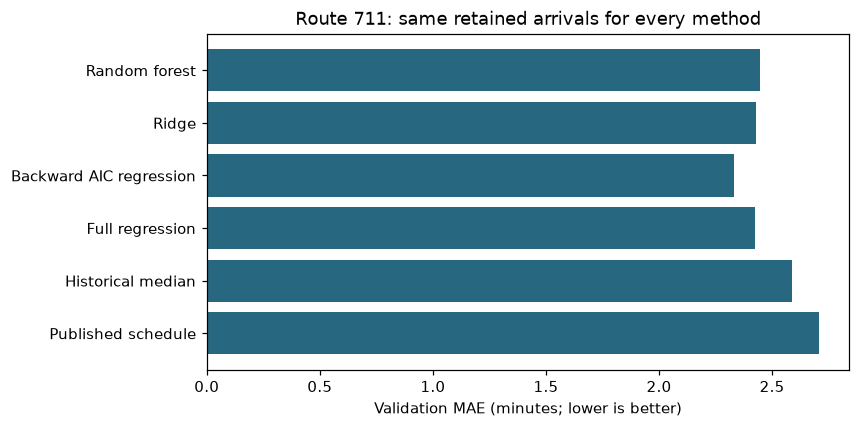

In [7]:
validation_predictions = validation[["source_row", "service_date", "weekday", "bus_id", "stop_id", "direction_id", "scheduled_arrival", "actual_arrival", TARGET]].copy()
score_rows = []
for name in METHODS:
    pred, settings = predict_procedure(name, train, validation)
    validation_predictions[name] = pred
    score_rows.append({"method": name, "chosen_by_training_folds": name == chosen_method, "settings": settings,
        "MAE_minutes": mean_absolute_error(validation[TARGET], pred), "RMSE_minutes": np.sqrt(mean_squared_error(validation[TARGET], pred)),
        "validation_R2": r2_score(validation[TARGET], pred)})
validation_results = pd.DataFrame(score_rows)
display(validation_results.round(3))
validation_predictions["predicted_arrival"] = validation_predictions.scheduled_arrival + pd.to_timedelta(validation_predictions[chosen_method], unit="min")
validation_predictions["absolute_error_minutes"] = (validation_predictions[chosen_method] - validation[TARGET]).abs()
display(validation_predictions[["source_row", "scheduled_arrival", "actual_arrival", "predicted_arrival", "absolute_error_minutes"]].head(8))
daily_rows = []
for day, g in validation_predictions.groupby("service_date"):
    row = {"service_date": day, "weekday": day.day_name(), "records": len(g)}
    for name in METHODS: row[name] = (g[name]-g[TARGET]).abs().mean()
    daily_rows.append(row)
daily_results = pd.DataFrame(daily_rows)
display(daily_results.round(3))
display(validation_predictions.groupby("direction_id").absolute_error_minutes.agg(["size", "mean"]).rename(columns={"mean": "MAE_minutes"}))
fig, ax = plt.subplots(figsize=(8,4))
ax.barh(validation_results.method, validation_results.MAE_minutes, color="#286780")
ax.set(xlabel="Validation MAE (minutes; lower is better)", title="Route 711: same retained arrivals for every method")
fig.tight_layout()
plt.show()

## Visual guide - demonstrate the results

The earlier bar chart compares **average** error across methods. The next figures show individual misses, stability across dates, and what the fitted model learns about hour.

These plots use the same training/validation split and chosen model. They do not tune it or access final-test outcomes.

### Graph 1. Actual versus predicted arrival delay

Each point is one validation arrival. A perfect prediction lies on the dashed diagonal. Compare using the schedule alone (zero predicted delay) with our training-fold-chosen method. Below the diagonal means we underestimated delay; above means we overestimated it. The axes show minutes relative to schedule, so a predicted delay of 3 minutes means adding 3 minutes to the published arrival time.

**Discuss:** which large delays remain difficult? Improving an average does not mean every arrival improves.

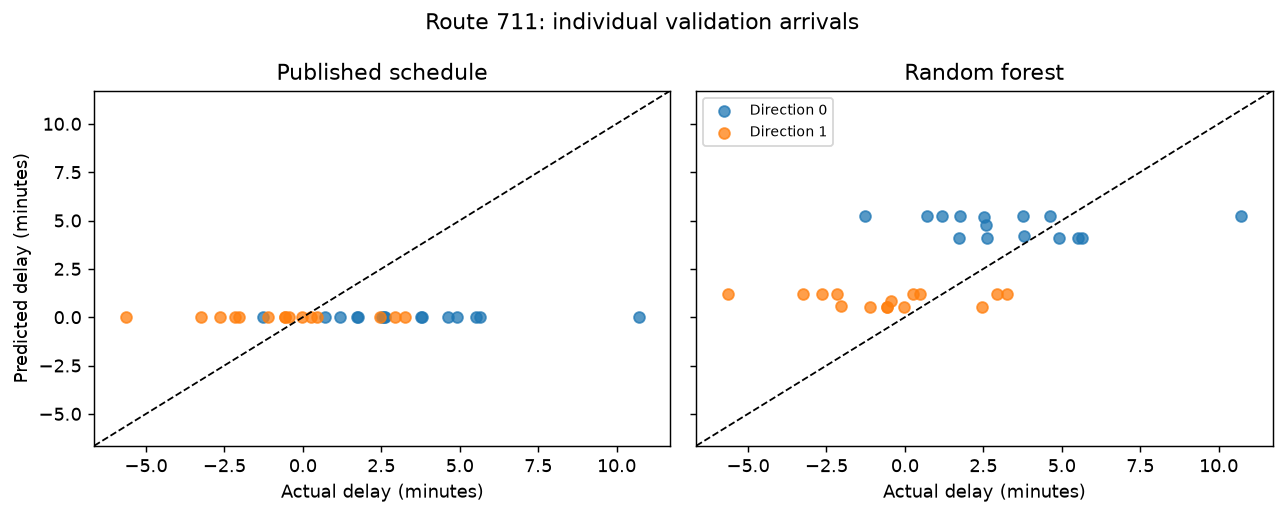

In [8]:
actual_delay = validation_predictions[TARGET].to_numpy()
model_delay = validation_predictions[chosen_method].to_numpy()
limits = [min(actual_delay.min(), model_delay.min(), 0) - 1,
          max(actual_delay.max(), model_delay.max(), 0) + 1]
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
for ax, name in zip(axes, ["Published schedule", chosen_method]):
    predicted = validation_predictions[name].to_numpy()
    for direction in sorted(validation_predictions.direction_id.unique()):
        mask = validation_predictions.direction_id.eq(direction)
        ax.scatter(actual_delay[mask], predicted[mask], alpha=0.75, label=f"Direction {direction}")
    ax.plot(limits, limits, "k--", linewidth=1)
    ax.set(xlim=limits, ylim=limits, xlabel="Actual delay (minutes)", title=name)
axes[0].set_ylabel("Predicted delay (minutes)")
axes[1].legend(fontsize=8)
fig.suptitle("Route 711: individual validation arrivals", fontsize=12)
fig.tight_layout()
plt.show()

### Graph 2. Error by validation date

Each group of bars describes one whole date. Lower bars mean better prediction. Counts above each group show how many arrivals contribute; some dates have fewer usable matches.

**Discuss:** does the model improve on the schedule every day, or is its overall improvement driven by one date? This is descriptive error analysis, not a reason to remove a difficult date.

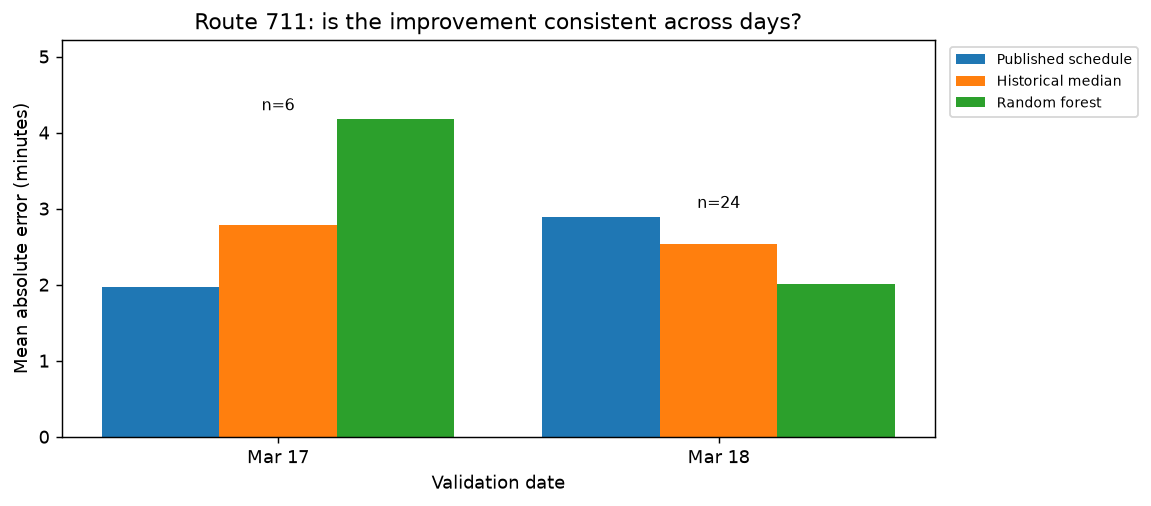

,arrivals,Published schedule,Historical median,Random forest
service_date,,,,
2023-03-17,6,1.972,2.789,4.174
2023-03-18,24,2.890,2.540,2.012


In [9]:
comparison_methods = list(dict.fromkeys(["Published schedule", "Historical median", chosen_method]))
daily = validation_predictions.groupby("service_date").size().to_frame("arrivals")
for name in comparison_methods:
    errors = (validation_predictions[name] - validation_predictions[TARGET]).abs()
    daily[name] = errors.groupby(validation_predictions.service_date).mean()
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(daily))
width = 0.8 / len(comparison_methods)
for j, name in enumerate(comparison_methods):
    ax.bar(x + (j - (len(comparison_methods)-1)/2)*width, daily[name], width, label=name)
for j, (_, row) in enumerate(daily.iterrows()):
    ax.text(j, row[comparison_methods].max()+0.12, f"n={int(row.arrivals)}", ha="center", fontsize=9)
ax.set_xticks(x, daily.index.strftime("%b %d"))
ax.set(xlabel="Validation date", ylabel="Mean absolute error (minutes)", title="Route 711: is the improvement consistent across days?")
ax.set_ylim(0, daily[comparison_methods].to_numpy().max()*1.25)
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
fig.tight_layout()
plt.show()
display(daily.round(3))

### Graph 3. What happens to predictions across the day?

Plot each direction across **hours observed on the most common training weekday**. Weekday is not a predictor here; restricting the plotted input support does not create a learned weekday effect. Model fitting uses all training dates; the plotted inputs vary scheduled hour while direction is fixed. We do not create combinations outside the observed support.

The dashed horizontal line is the historical median prediction. Separate direction curves also represent different Walmart stop locations. This is a demonstration of the model's learned associations, **not evidence that changing the hour causes a delay**, and not an evaluation on unseen data. No recent actual arrival or passenger counts enter these inputs.

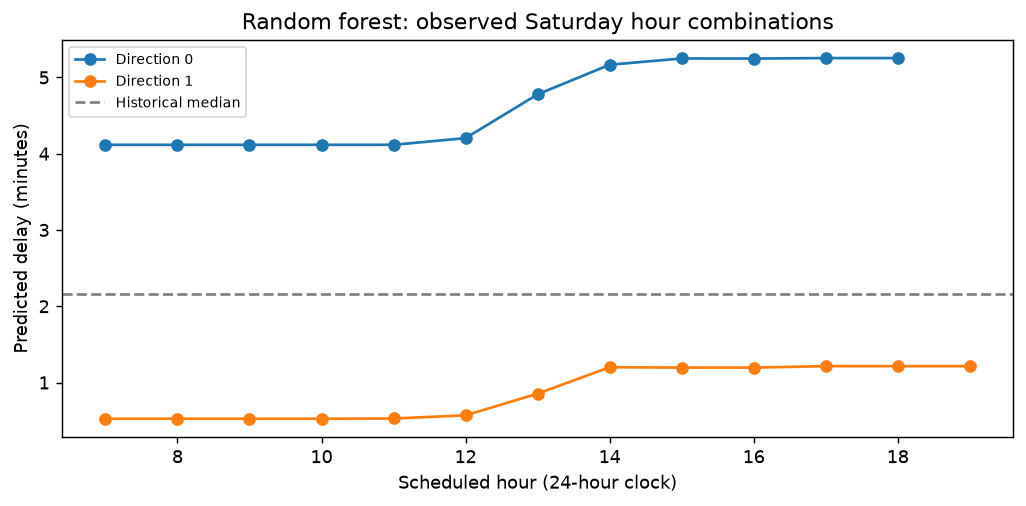

,direction_id,scheduled_hour,predicted_delay_minutes
0,0,7,4.116
1,0,8,4.116
2,0,9,4.116
3,0,10,4.116
4,0,11,4.116
5,0,12,4.204
6,0,13,4.778
7,0,14,5.166
8,0,15,5.248
9,0,16,5.247


In [10]:
demo_weekday = train.weekday.mode().iloc[0]
demo_inputs = (train.loc[train.weekday.eq(demo_weekday), GROUPS]
               .drop_duplicates().sort_values(["direction_id", "scheduled_hour"]))
demo_prediction, demo_settings = predict_procedure(chosen_method, train, demo_inputs)
demo = demo_inputs.copy()
demo["predicted_delay_minutes"] = demo_prediction
fig, ax = plt.subplots(figsize=(8, 4))
for direction, part in demo.groupby("direction_id"):
    ax.plot(part.scheduled_hour, part.predicted_delay_minutes, marker="o", label=f"Direction {direction}")
ax.axhline(train[TARGET].median(), color="gray", linestyle="--", label="Historical median")
ax.set(xlabel="Scheduled hour (24-hour clock)", ylabel="Predicted delay (minutes)",
       title=f"{chosen_method}: observed {demo_weekday} hour combinations")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
display(demo.reset_index(drop=True).round(3))

### How to present these figures

1. Begin with the average-error bar chart: which approach has the smallest average miss?
2. Show the scatter plots: averages hide large individual misses.
3. Show the date bars: ask whether the benefit is stable across days.
4. Show the hour curves: explain what the model predicts when known schedule inputs change.

Always mention that matches are provisional and only the retained Walmart timepoints are represented. The optional PNG files in the download package can be used in slides.

### Check whether validation inputs were seen during training

The model knows direction and hour, but has only a short training history. Count whether each direction/hour combination appeared before. This diagnostic is calculated **after fitting** to explain evaluation difficulty; it does not change the split, remove records, or select the model.

All six Friday validation arrivals use direction/hour combinations absent from training. The 24 Saturday arrivals have previously observed combinations. Friday therefore tests both a new operating weekday and unsupported direction/hour inputs. We cannot attribute its poorer errors to weekday alone.

In [11]:
# This is a support diagnostic only; it never becomes a model predictor.
observed_inputs = train[GROUPS].drop_duplicates().assign(observed_in_training=True)
support_check = validation[["source_row", "service_date", "weekday", *GROUPS]].merge(
    observed_inputs, on=GROUPS, how="left", validate="many_to_one")
support_check["observed_in_training"] = support_check.observed_in_training.fillna(False).astype(bool)
support_table = support_check.groupby(["service_date", "weekday"]).agg(
    arrivals=("source_row", "size"), previously_observed_inputs=("observed_in_training", "sum"))
support_table["new_direction_hour_combinations"] = support_table.arrivals - support_table.previously_observed_inputs
display(support_table)
display(train.groupby("direction_id").scheduled_hour.agg(["min", "max"]).rename(columns={"min":"training_first_hour", "max":"training_last_hour"}))

,,arrivals,previously_observed_inputs,new_direction_hour_combinations
service_date,weekday,,,
2023-03-17,Friday,6,0,6
2023-03-18,Saturday,24,24,0


,training_first_hour,training_last_hour
direction_id,,
0,7,18
1,7,19


## 6. Results interpreted

### How much data is actually modeled?
The workbook has **4,076 stop visits**, **5 buses**, and seven dates. We retain **110 provisional intermediate arrivals**: **80 training** and **30 validation** observations. These are the two directional Walmart stops, not every stop. **228 other timepoint records** are held for review. Outliers flagged by training-only IQR are retained.

### What did the numbering check change?
Raw sequence 19 at return Walmart corresponds to scheduled sequence 16. The equality join used on other routes would silently miss this stop. We align unique physical stop IDs and require consistent ordered patterns and other-timepoint evidence instead. Missing stops and numbering offsets are distinguished from actual order contradictions. All assignments remain provisional; archived schedule compatibility has not been independently confirmed.

### What do the regression statistics say?
Full-model training R² **0.298**, adjusted R² **0.280**, classical F **16.35**, ordinary F-test p **1.2e-06**, AIC **408.63**, BIC **415.78**. Only four training days support these results, so do not make strong significance claims. Backward AIC retains **direction_id**, with AIC **407.03** and BIC **411.79**.

### Which procedure won?
Training folds choose **Random forest**, with MAE **2.016 minutes**. Its validation MAE is **2.444 minutes**. The lowest validation MAE is **2.332 minutes** from **Backward AIC regression**. If these differ, retain the original selection rule and report the disagreement. Two folds and two validation dates are too little for a definitive best-model claim.

### Is it better than the schedule?
Schedule validation MAE is **2.706 minutes**. The median scores **2.589**, a **4.3% reduction** (a negative reduction means worse). The training-fold-selected procedure scores **2.444**, a **9.7% reduction**. These compare with published times, not live Navigator predictions, and apply only to retained provisional matches.

### Did complexity help?
Validation MAEs: full regression **2.424**, backward regression **2.332**, ridge **2.430**, forest **2.444 minutes**. Compare them with both simple baselines. AIC/BIC improvement and small p-values do not guarantee future-date improvement.

### What does this add to the research?
It tests the procedure under different service periods and exposes a real data-integration issue. It does not establish an independent fourth-route generalization result: routes overlap geographically, splits differ, only seven dates exist, and schedule assignments are inferred. Compare per-route baseline improvements before pooling.

### Practical synthesis

- **The training-fold choice is random forest:** validation MAE is about **2 minutes 27 seconds**, compared with **2 minutes 42 seconds** for the timetable: roughly **16 seconds less error**, or **9.7%**. This is the selection rule fixed before viewing validation.
- **Backward regression has the lowest validation MAE:** about **2 minutes 20 seconds**, but it was not the training-fold winner. Report that result descriptively rather than switching the chosen model after looking at validation.
- **The two operating periods tell different stories:** on six Friday arrivals, forest MAE is **4.17 minutes**, worse than the timetable's **1.97 minutes**. On 24 Saturday arrivals, it is **2.01 minutes**, better than **2.89 minutes**. The overall average gives Saturday four times as much weight because it has four times as many observations.
- **Friday is outside observed input support:** all six Friday direction/hour combinations were absent from training. Saturday's 24 combinations were represented. That, along with different service conditions, limits the interpretation of Friday performance. We did not remove those hard cases.
- **Backward selection removed hour:** direction alone remained. In the full training regression, direction 1 is associated with about **3.88 minutes less delay** than direction 0, conditional on hour; the estimated hour slope is only **+0.067 minutes per hour** (about 4 seconds). These are sample associations at two different locations, not causal effects.
- **This is a small extension, not a final claim:** four training days, two validation dates, a single reserved date, and provisional schedule alignment leave substantial uncertainty. A bigger row count would not replace more independent operating days.


## 7. Research questions - answered

**Why did we change the sequence matching rule?**  
The recorded numbering disagrees with GTFS. Matching on physical stop identity and consistent travel order preserves evidence; pretending the numbers are equal would lose or misassign records. Both sequence columns are retained for review.

**Why not copy the ten/three/four-day split?**  
Only seven days exist. Four train, two validate, one reserve is transparent but weak. We do not reuse one day on both sides of a split or randomly split nearby arrivals.

**Why leave weekday out?**  
Training contains only Saturday/Sunday and validation adds Friday. There is no learned Friday effect. Using direction/hour avoids arbitrary unseen-weekday encoding, but does not solve the Friday operating-period shift. The daily comparison reports it openly.

**Why not include stop ID as well as direction?**  
At the two modeled Walmart timepoints, stop and direction encode the same split. They are redundant in this sample.

**Did we delete extreme delays to improve results?**  
No. IQR flags use training data and unusual retained labels stay included. Matching itself has a 20-minute window and evidence requirements, which can censor severe or uncertain cases; report that separate limitation.

**Can we trust the p-values?**  
Four days are far too few for strong inferential claims. Ordinary and day-clustered uncertainty are descriptive sensitivity checks. Prediction should be assessed on later dates, with substantial uncertainty acknowledged.

**Where could look-ahead bias enter?**  
Future arrivals used as predictors, preprocessing/selection fitted on evaluation rows, or tuning using held-out outcomes. Here only schedule-known direction/hour enter. Historical trajectory evidence supports provisional labels and is not claimed available live.

**Can we compare its MAE directly with Route 7/3/11?**  
Not as a fair ranking: days, service periods, timed stops, inclusion rules, and sample counts differ. Compare against its own schedule baseline and report each route separately.

**What should we do after all four routes?**  
Resolve label concerns, freeze procedures, and complete the reserved evaluations. Then compare separate versus pooled models using compatible targets and shared calendar boundaries where feasible. A route-held-out experiment must preserve chronology and use transferable predictors. Route 711's different dates and weekend focus make naive pooling misleading.

**What are the sources?**  
Richard Borzi / University of Florida, supplied by Gainesville RTS, CC BY 4.0: [Route 711 data](https://zenodo.org/records/10034622). Historical [Spring 2023 GTFS](https://www.ftis.org/PostFileDownload.aspx?id=602A0). Preserve attribution when sharing derived work.

## Optional - save outputs

Uncomment if desired. Originals remain unchanged. Split, linkage, and outlier fields belong in the research record, not the model inputs.

In [12]:
# cleaned.to_csv("Route711_Development.csv", index=False)
# held.to_csv("Route711_Held_For_Review.csv", index=False)
# validation_results.to_csv("Route711_Validation_Results.csv", index=False)
# fold_results.to_csv("Route711_Date_Folds.csv", index=False)